# Erasmus+ Öğrenci Hareketliliği Ağı – Analiz Defteri

**Öğrenci:** Müesser İrem Gecici · 2516016027 · Sosyal Ağ Analizi (2026-2027 Güz)

**Araştırma sorusu:** Türkiye Erasmus ağında "gönderen" mi "alan" mı? Akışlar mesafe ve ülke büyüklüğüyle açıklanabiliyor mu?

Defterin akışı:
1. Veri: ham Excel'i indir, yükseköğretim öğrencilerini süz, ağları kur
2. Temel ağ ölçüleri ve derece dağılımı (kuvvet yasası testi)
3. Merkeziyetler (ilk 10 tabloları, Spearman korelasyonu)
4. Topluluk tespiti (Louvain + Leiden, kararlılık)
5. Null model karşılaştırması (100 rastgele ağ, z-skorları)
6. İleri yöntem: karşılıklılık ve giriş/çıkış dengesizliği, çekim modeli, yıllar arası değişim
7. Görselleştirme için dışa aktarma

Tüm rastgele işlemler `SEED = 42` ile sabitlenmiştir.

In [1]:
import os, json, math, time, warnings
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats, optimize, special
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
YIL = 2022
AGIRLIK = "Actual Participants (Contracted Projects)"
for klasor in ["data/raw", "data/processed", "output", "fig"]:
    os.makedirs(klasor, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
SONUC = {}  # rapor ve görselleştirme için tüm sayılar buraya yazılır
print("networkx", nx.__version__, "| pandas", pd.__version__)

networkx 3.7 | pandas 3.0.5


## 1. Veri toplama ve ağ kurma

Kaynak: [data.europa.eu – Erasmus+ Mobility Raw Data](https://data.europa.eu/data/datasets/erasmus-mobility-raw-data) (DG EAC, lisans: European Commission reuse notice / provisional data).
Fonksiyon ham dosyayı yoksa indirir, yükseköğretim öğrencisi satırlarını süzer ve sonucu `data/processed/` altına önbellekler.

**Kararlar ve gerekçeleri**
- *Filtre:* `Field = Higher Education` ve `Participant Profile = Learner(s)`. Soru öğrenci hareketliliği; personel ve okul/gençlik değişimleri ayrı programlardır.
- *Düğüm:* kurum ağında `ÜLKE | KURUM` (aynı kısaltmalı farklı ülke kurumlarını ayırmak için), ülke ağında ülke kodu.
- *Kenar:* gönderen → alan, **yönlü**; çünkü soru tam olarak giden/gelen farkıdır.
- *Ağırlık:* öğrenci sayısı (`Actual Participants`).
- Kurum adı "-" olan satırlar kurum ağına alınmaz (ülke ağında kalır); ülke içi akışlar (öz-döngü) çıkarılır.
- **Ad sistemi sorunu:** 2022 dosyası iki program döneminin kayıtlarını birlikte içerir. 2014-2020 projelerinde kurumlar uzun adla
  ("UNIVERSIDAD DE GRANADA"), 2021-2027 projelerinde (faaliyet kodu `HE-…`) kısa kodla ("UGR") yazılmıştır; yani aynı üniversite iki ayrı düğüm olur.
  Bu yüzden **kurum ağı yalnızca 2021-2027 dönemi kayıtlarından** kurulur (tutarlı ad sistemi). Ülke ağı tüm kayıtları kullanır.

In [2]:
def ham_indir(yil):
    import requests
    yol = f"data/raw/Erasmus-KA1-Mobility-Data-{yil}.xlsx"
    if not os.path.exists(yol):
        url = f"https://ec.europa.eu/assets/eac/erasmus-plus/statistics/mobility/Erasmus-KA1-Mobility-Data-{yil}.xlsx"
        r = requests.get(url, stream=True, timeout=600)
        r.raise_for_status()
        with open(yol, "wb") as f:
            for parca in r.iter_content(1 << 20):
                f.write(parca)
    return yol


def temizle(s):
    return s.astype(str).str.strip().str.upper()


def ogrenci_verisi(yil):
    """Yükseköğretim öğrenci satırlarını döndürür (önbellekli)."""
    onbellek = f"data/processed/ogrenci_{yil}.csv.gz"
    if os.path.exists(onbellek):
        return pd.read_csv(onbellek, keep_default_na=False)
    df = pd.read_excel(ham_indir(yil), usecols=range(19))
    ogr = df[(df["Field"] == "Higher Education")
             & (df["Participant Profile"].astype(str).str.lower().str.startswith("learner"))].copy()
    out = pd.DataFrame({
        "kaynak_ulke": ogr["Sending Country"].astype(str).str[:2],
        "hedef_ulke": ogr["Receiving Country"].astype(str).str[:2],
        "kaynak_kurum": temizle(ogr["Sending Organization"]),
        "hedef_kurum": temizle(ogr["Receiving Organization"]),
        "faaliyet": ogr["Activity (mob)"].astype(str),
        "kisi": pd.to_numeric(ogr[AGIRLIK], errors="coerce").fillna(0).astype(int),
        "toplam_satir": len(df),
    })
    out.to_csv(onbellek, index=False, compression="gzip")
    return out


def kenar_listeleri(ogr):
    u = ogr.groupby(["kaynak_ulke", "hedef_ulke"])["kisi"].sum().reset_index()
    u.columns = ["source", "target", "weight"]
    u = u[u.source != u.target].sort_values("weight", ascending=False).reset_index(drop=True)
    k = ogr[ogr.faaliyet.str.startswith("HE-")]  # yalnızca 2021-2027 dönemi (kısa kod ad sistemi)
    k = k[(~k.kaynak_kurum.isin(["-", "", "NAN"])) & (~k.hedef_kurum.isin(["-", "", "NAN"]))].copy()
    k["source"] = k.kaynak_ulke + " | " + k.kaynak_kurum
    k["target"] = k.hedef_ulke + " | " + k.hedef_kurum
    k = k.groupby(["source", "target"])["kisi"].sum().reset_index().rename(columns={"kisi": "weight"})
    k = k[k.source != k.target].sort_values("weight", ascending=False).reset_index(drop=True)
    return u, k


def yonlu_ag(kenar):
    G = nx.DiGraph()
    G.add_weighted_edges_from(kenar[["source", "target", "weight"]].itertuples(index=False))
    return G


def yonsuz_ag(G):
    """İki yöndeki akışları toplayarak yönsüz ağırlıklı ağ üretir."""
    U = nx.Graph()
    for a, b, w in G.edges(data="weight"):
        if U.has_edge(a, b):
            U[a][b]["weight"] += w
        else:
            U.add_edge(a, b, weight=w)
    return U


t0 = time.time()
ogr = ogrenci_verisi(YIL)
ulke_kenar, kurum_kenar = kenar_listeleri(ogr)
ulke_kenar.to_csv(f"output/kenar_listesi_ulke_{YIL}.csv", index=False)
kurum_kenar.to_csv(f"output/kenar_listesi_kurum_{YIL}.csv", index=False)

G = yonlu_ag(kurum_kenar)          # ana ağ: kurum düzeyi, yönlü
U = yonsuz_ag(G)                   # topluluk ve null model için yönsüz hali
GC = yonlu_ag(ulke_kenar)          # ülke düzeyi, yönlü
for n in G:
    G.nodes[n]["ulke"] = n[:2]
nx.write_graphml(G, f"output/ag_kurum_{YIL}.graphml")
nx.write_graphml(GC, f"output/ag_ulke_{YIL}.graphml")

SONUC["veri"] = {
    "ham_satir": int(ogr.toplam_satir.iloc[0]), "ogrenci_satir": int(len(ogr)), "ogrenci": int(ogr.kisi.sum()),
    "yeni_donem_ogrenci": int(ogr.loc[ogr.faaliyet.str.startswith("HE-"), "kisi"].sum()),
    "eski_donem_ogrenci": int(ogr.loc[~ogr.faaliyet.str.startswith("HE-"), "kisi"].sum()),
    "kurum_agi_ogrenci": int(kurum_kenar.weight.sum()),
}
print(SONUC["veri"], f"({time.time()-t0:.0f} sn)")

{'ham_satir': 867767, 'ogrenci_satir': 349634, 'ogrenci': 365590, 'yeni_donem_ogrenci': 268984, 'eski_donem_ogrenci': 96606, 'kurum_agi_ogrenci': 193465} (1 sn)


## 2. Temel ağ ölçüleri

Büyük ağda ortalama en kısa yol ve çap, en büyük zayıf bileşenden rastgele seçilen 500 başlangıç düğümüyle (BFS) örneklenerek hesaplanır; çap bu nedenle bir **alt sınırdır**.

In [3]:
def yol_ornekle(H, k=500, seed=SEED):
    """Yönsüz bağlı H'de k kaynaktan BFS: ortalama en kısa yol ve gözlenen en büyük mesafe."""
    r = np.random.default_rng(seed)
    dugumler = list(H.nodes())
    kaynaklar = r.choice(len(dugumler), size=min(k, len(dugumler)), replace=False)
    toplam, sayi, en_buyuk = 0, 0, 0
    for i in kaynaklar:
        d = nx.single_source_shortest_path_length(H, dugumler[i])
        vals = np.fromiter(d.values(), dtype=np.int64)
        toplam += vals.sum(); sayi += len(vals) - 1; en_buyuk = max(en_buyuk, int(vals.max()))
    return toplam / sayi, en_buyuk


def temel_olculer(G, U, ornek=True):
    wcc = max(nx.weakly_connected_components(G), key=len)
    scc = max(nx.strongly_connected_components(G), key=len)
    H = U.subgraph(wcc)
    if ornek:
        ort_yol, cap = yol_ornekle(H)
    else:
        ort_yol, cap = nx.average_shortest_path_length(H), nx.diameter(H)
    return {
        "dugum": G.number_of_nodes(), "kenar": G.number_of_edges(),
        "yogunluk": nx.density(G),
        "zayif_bilesen": nx.number_weakly_connected_components(G), "en_buyuk_zayif": len(wcc),
        "guclu_bilesen": nx.number_strongly_connected_components(G), "en_buyuk_guclu": len(scc),
        "ort_en_kisa_yol": ort_yol, "cap": cap,
        "ort_kumelenme": nx.average_clustering(U), "gecislilik": nx.transitivity(U),
        "assortativity_yonsuz": nx.degree_assortativity_coefficient(U),
        "assortativity_out_in": nx.degree_assortativity_coefficient(G, x="out", y="in"),
        "ort_derece": 2 * U.number_of_edges() / U.number_of_nodes(),
    }

SONUC["temel_kurum"] = temel_olculer(G, U, ornek=True)
SONUC["temel_ulke"] = temel_olculer(GC, yonsuz_ag(GC), ornek=False)
tablo = pd.DataFrame({"Kurum ağı": SONUC["temel_kurum"], "Ülke ağı": SONUC["temel_ulke"]})
print(tablo.to_string(float_format=lambda x: f"{x:,.4f}"))

                       Kurum ağı   Ülke ağı
dugum                13,167.0000   176.0000
kenar                69,839.0000 3,060.0000
yogunluk                  0.0004     0.0994
zayif_bilesen           275.0000     1.0000
en_buyuk_zayif       12,286.0000   176.0000
guclu_bilesen        11,657.0000    44.0000
en_buyuk_guclu        1,508.0000   133.0000
ort_en_kisa_yol           3.6698     1.9782
cap                      12.0000     3.0000
ort_kumelenme             0.0488     0.7730
gecislilik                0.1562     0.4382
assortativity_yonsuz     -0.1186    -0.6328
assortativity_out_in     -0.0888    -0.5932
ort_derece                8.8834    22.6250


## 2b. Derece dağılımı ve kuvvet yasası testi

Clauset, Shalizi & Newman (2009) yöntemi: `x_min`, Kolmogorov–Smirnov uzaklığını en aza indiren değer seçilir; üs (α) en çok olabilirlik ile tahmin edilir; kuvvet yasası, log-normal ve üstel dağılımla log-olabilirlik oranı (Vuong) testiyle karşılaştırılır.
Bu, `powerlaw` paketinin varsayılan (sürekli yaklaşım) yöntemiyle aynıdır. Paket kuruluysa aşağıdaki hücre sonuçları onunla da karşılaştırır.

In [4]:
def guc_yasasi_uyumu(x, en_az_kuyruk=50):
    x = np.sort(np.asarray(x, dtype=float)); x = x[x > 0]
    adaylar = np.unique(x)
    en_iyi = None
    for xmin in adaylar:
        kuyruk = x[x >= xmin]; n = len(kuyruk)
        if n < en_az_kuyruk:
            break
        alpha = 1 + n / np.sum(np.log(kuyruk / xmin))
        emp = np.arange(n) / n
        model = 1 - (kuyruk / xmin) ** (1 - alpha)
        D = np.max(np.abs(emp - model))
        if en_iyi is None or D < en_iyi[2]:
            en_iyi = (xmin, alpha, D, n)
    xmin, alpha, D, n = en_iyi
    k = x[x >= xmin]
    ll_pl = np.log(alpha - 1) - np.log(xmin) - alpha * np.log(k / xmin)
    lam = 1 / np.mean(k - xmin)
    ll_exp = np.log(lam) - lam * (k - xmin)

    def nll_ln(p):
        mu, s = p
        if s <= 0:
            return 1e12
        z = (np.log(k) - mu) / s
        norm = stats.norm.sf((np.log(xmin) - mu) / s)
        return -np.sum(stats.norm.logpdf(z) - np.log(k * s) - np.log(max(norm, 1e-300)))
    res = optimize.minimize(nll_ln, [np.mean(np.log(k)), np.std(np.log(k))], method="Nelder-Mead")
    mu, s = res.x
    z = (np.log(k) - mu) / s
    ll_ln = stats.norm.logpdf(z) - np.log(k * s) - np.log(stats.norm.sf((np.log(xmin) - mu) / s))

    def vuong(l1, l2):
        d = l1 - l2; R = d.sum(); sigma = d.std()
        p = special.erfc(abs(R) / (np.sqrt(2 * len(d)) * sigma)) if sigma > 0 else 1.0
        return float(R), float(p)
    R_ln, p_ln = vuong(ll_pl, ll_ln)
    R_exp, p_exp = vuong(ll_pl, ll_exp)
    return {"xmin": float(xmin), "alpha": float(alpha), "KS": float(D), "kuyruk_n": int(n),
            "R_lognormal": R_ln, "p_lognormal": p_ln, "R_ustel": R_exp, "p_ustel": p_exp,
            "lognormal_mu": float(mu), "lognormal_sigma": float(s)}


dereceler = np.array([d for _, d in U.degree()])
SONUC["derece_dagilimi"] = guc_yasasi_uyumu(dereceler)
SONUC["derece_dagilimi"].update({"max_derece": int(dereceler.max()), "medyan_derece": float(np.median(dereceler)),
                                 "derece1_orani": float(np.mean(dereceler == 1))})
print(json.dumps(SONUC["derece_dagilimi"], indent=1))

try:
    import powerlaw
    fit = powerlaw.Fit(dereceler, verbose=False)
    print("powerlaw paketi: alpha =", round(fit.power_law.alpha, 3), "xmin =", fit.power_law.xmin,
          "| PL vs lognormal (R, p) =", fit.distribution_compare("power_law", "lognormal"))
except ImportError:
    print("powerlaw paketi kurulu değil; yukarıdaki eşdeğer uygulama kullanıldı.")

{
 "xmin": 149.0,
 "alpha": 3.4073943959575406,
 "KS": 0.06116821380966164,
 "kuyruk_n": 190,
 "R_lognormal": -3.30687110204223,
 "p_lognormal": 0.11593603993868705,
 "R_ustel": -1.7602590763255392,
 "p_ustel": 0.6641338831627357,
 "lognormal_mu": 4.328347731553039,
 "lognormal_sigma": 0.7585308211669609,
 "max_derece": 811,
 "medyan_derece": 1.0,
 "derece1_orani": 0.7600060757955495
}
powerlaw paketi kurulu değil; yukarıdaki eşdeğer uygulama kullanıldı.


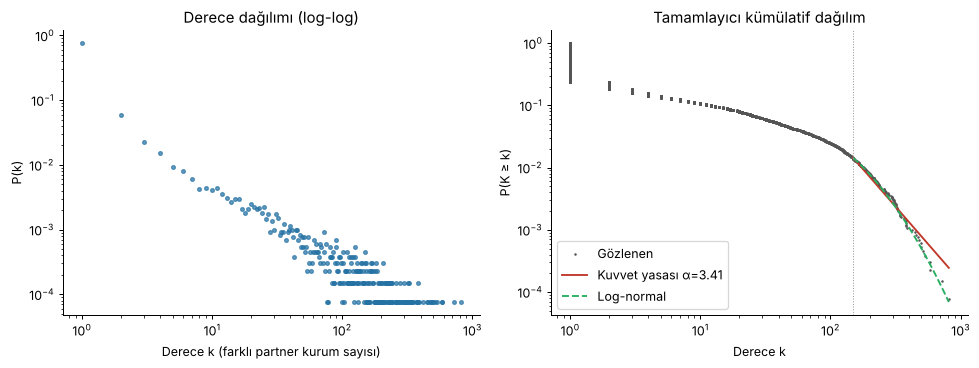

In [5]:
dd = SONUC["derece_dagilimi"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sayac = Counter(dereceler); kk = np.array(sorted(sayac)); pk = np.array([sayac[v] for v in kk]) / len(dereceler)
ax[0].loglog(kk, pk, "o", ms=3, color="#2471a3", alpha=.7)
ax[0].set_xlabel("Derece k (farklı partner kurum sayısı)"); ax[0].set_ylabel("P(k)")
ax[0].set_title("Derece dağılımı (log-log)")
xs = np.sort(dereceler); ccdf = 1 - np.arange(len(xs)) / len(xs)
ax[1].loglog(xs, ccdf, ".", ms=2, color="#555", label="Gözlenen")
kuyruk_orani = np.mean(dereceler >= dd["xmin"])
xx = np.logspace(np.log10(dd["xmin"]), np.log10(xs.max()), 50)
ax[1].loglog(xx, kuyruk_orani * (xx / dd["xmin"]) ** (1 - dd["alpha"]), "-", color="#c0392b",
             label=f"Kuvvet yasası α={dd['alpha']:.2f}")
ln_ccdf = stats.norm.sf((np.log(xx) - dd["lognormal_mu"]) / dd["lognormal_sigma"]) / \
    stats.norm.sf((np.log(dd["xmin"]) - dd["lognormal_mu"]) / dd["lognormal_sigma"])
ax[1].loglog(xx, kuyruk_orani * ln_ccdf, "--", color="#27ae60", label="Log-normal")
ax[1].axvline(dd["xmin"], color="#999", lw=.8, ls=":")
ax[1].set_xlabel("Derece k"); ax[1].set_ylabel("P(K ≥ k)"); ax[1].set_title("Tamamlayıcı kümülatif dağılım"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig/derece_dagilimi.png", dpi=200); plt.show()

## 3. Merkeziyetler

- **Derece / güç:** kaç farklı partner, kaç öğrenci (giriş = gelen, çıkış = giden).
- **Betweenness:** yönlü, ağırlıksız; 36 bin düğümde 1.000 rastgele kaynakla örneklenir (`seed=42`).
- **Closeness:** yönsüz, en yüksek dereceli 2.000 kurum için (her biri için tam BFS).
- **PageRank:** yönlü ve öğrenci sayısıyla ağırlıklı (öğrenci "çeken" kurumlar).

Spearman korelasyonu, closeness'ın hesaplandığı 2.000 kurum üzerinden verilir.

In [6]:
t0 = time.time()
derece = dict(U.degree())
giris = dict(G.in_degree(weight="weight")); cikis = dict(G.out_degree(weight="weight"))
btw = nx.betweenness_centrality(G, k=1000, seed=SEED, normalized=True)
pr = nx.pagerank(G, weight="weight")
ust = sorted(derece, key=derece.get, reverse=True)[:2000]
wcc_U = U.subgraph(max(nx.connected_components(U), key=len))
clo = {n: nx.closeness_centrality(wcc_U, u=n) for n in ust if n in wcc_U}
merk = pd.DataFrame({"derece": derece, "gelen_ogrenci": giris, "giden_ogrenci": cikis,
                     "betweenness": btw, "pagerank": pr, "closeness": clo})
merk["ulke"] = merk.index.str[:2]
merk.index.name = "kurum"
merk.to_csv(f"output/merkeziyet_kurum_{YIL}.csv")
print(f"merkeziyetler {time.time()-t0:.0f} sn")

ilk10 = {}
for olcu in ["derece", "gelen_ogrenci", "giden_ogrenci", "betweenness", "closeness", "pagerank"]:
    ilk10[olcu] = merk[olcu].sort_values(ascending=False).head(10)
    print(f"\n--- İlk 10: {olcu} ---"); print(ilk10[olcu].to_string())

olcu_sutun = ["derece", "gelen_ogrenci", "giden_ogrenci", "betweenness", "closeness", "pagerank"]
spearman = merk.loc[list(clo)][olcu_sutun].corr(method="spearman")
print("\nSpearman korelasyonu (2.000 kurum):"); print(spearman.round(2).to_string())
SONUC["merkeziyet"] = {"ilk10": {k: [[i, float(v)] for i, v in s.items()] for k, s in ilk10.items()},
                       "spearman": spearman.round(3).to_dict()}

# Türk kurumları
tr = merk[merk.ulke == "TR"].sort_values("pagerank", ascending=False)
SONUC["merkeziyet"]["tr_kurum_sayisi"] = int(len(tr))
SONUC["merkeziyet"]["tr_ilk5_pagerank"] = [[i, int(r.giden_ogrenci), int(r.gelen_ogrenci), int((merk.pagerank > r.pagerank).sum()) + 1]
                                          for i, r in tr.head(5).iterrows()]
print("\nTürk kurumları (PageRank sırası):"); print(tr.head(5)[["derece", "giden_ogrenci", "gelen_ogrenci", "pagerank"]].to_string())

merkeziyetler 83 sn

--- İlk 10: derece ---
kurum
IT | UNIBO                                   811
SI | UL                                      719
ES | UCM                                     586
ES | UVEG                                    579
CZ | CU                                      530
EL | ARISTOTLE UNIVERSITY OF THESSALONIKI    518
IT | UNIFI                                   500
PT | ULISBOA                                 492
ES | UGR                                     481
HR | UNIVERSITY OF ZAGREB UNIZG              471

--- İlk 10: gelen_ogrenci ---
kurum
IT | UNIBO      2353
PT | ULISBOA    2225
ES | UVEG       2096
ES | UGR        1809
CZ | CU         1567
NO | NTNU       1547
IT | POLIMI     1488
IT | UNIPD      1474
SI | UL         1362
ES | UPV        1267

--- İlk 10: giden_ogrenci ---
kurum
IT | UNIBO        2932
ES | UVEG         1911
ES | UCM          1769
DE | TUM          1705
IT | UNIPD        1669
IT | POLIMI       1643
ES | UGR          1437
ES | USE       

In [7]:
# Ülke ağı merkeziyetleri (küçük ağ, tam hesap)
UC = yonsuz_ag(GC)
um = pd.DataFrame({
    "giden": dict(GC.out_degree(weight="weight")), "gelen": dict(GC.in_degree(weight="weight")),
    "derece": dict(UC.degree()), "betweenness": nx.betweenness_centrality(GC),
    "closeness": nx.closeness_centrality(UC), "pagerank": nx.pagerank(GC, weight="weight"),
}).fillna(0)
for c in ["giden", "gelen", "pagerank", "betweenness", "closeness", "derece"]:
    um[c + "_sira"] = um[c].rank(ascending=False, method="min").astype(int)
um.index.name = "ulke"
um.to_csv(f"output/merkeziyet_ulke_{YIL}.csv")
print(um.sort_values("pagerank", ascending=False).head(10)[["giden", "gelen", "derece", "betweenness", "pagerank"]].round(4).to_string())
SONUC["ulke_tr"] = um.loc["TR"].to_dict()
print("\nTürkiye:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in SONUC["ulke_tr"].items()})

      giden  gelen  derece  betweenness  pagerank
ulke                                             
ES    48279  57699     138       0.1341    0.1342
IT    43967  37589     113       0.0582    0.0877
DE    48949  34996     119       0.0819    0.0849
FR    53843  32618     121       0.0915    0.0798
PT    10440  18596      83       0.0330    0.0428
NL    18237  16105     100       0.0436    0.0382
BE    12408  14794     113       0.0622    0.0340
UK     7757  14433      73       0.0106    0.0335
PL    13000  15388      96       0.0171    0.0317
CZ     7770  10851      89       0.0338    0.0262

Türkiye: {'giden': 16214.0, 'gelen': 6045.0, 'derece': 89.0, 'betweenness': 0.0288, 'closeness': 0.6705, 'pagerank': 0.0151, 'giden_sira': 6.0, 'gelen_sira': 19.0, 'pagerank_sira': 18.0, 'betweenness_sira': 10.0, 'closeness_sira': 10.0, 'derece_sira': 10.0}


## 4. Topluluk tespiti

Yönsüz, ağırlıklı kurum ağı üzerinde Louvain ve Leiden (modülerlik amaç fonksiyonu, çözünürlük 1).
Kararlılık: her algoritma 10 farklı tohumla çalıştırılır; ikili karşılaştırmaların ortalama NMI ve ARI değerleri raporlanır.

In [8]:
def etiket(bolum, dugumler):
    harita = {}
    for i, c in enumerate(sorted(bolum, key=len, reverse=True)):
        for n in c:
            harita[n] = i
    return np.array([harita[n] for n in dugumler])


dugumler = list(U.nodes())
TOHUMLAR = list(range(SEED, SEED + 10))
onbellek = "output/onbellek_topluluk.json"
if os.path.exists(onbellek):
    kayit = json.load(open(onbellek))
    print("Topluluk sonuçları önbellekten yüklendi (silerseniz yeniden hesaplanır).")
else:
    kayit = {"louvain": [], "leiden": []}
    for s in TOHUMLAR:
        t0 = time.time()
        lv = nx.community.louvain_communities(U, weight="weight", seed=s)
        ld = nx.community.leiden_communities(U, weight="weight", seed=s, metric="modularity")
        kayit["louvain"].append({"etiket": etiket(lv, dugumler).tolist(), "Q": nx.community.modularity(U, lv, weight="weight")})
        kayit["leiden"].append({"etiket": etiket(ld, dugumler).tolist(), "Q": nx.community.modularity(U, ld, weight="weight")})
        print(f"tohum {s}: Louvain Q={kayit['louvain'][-1]['Q']:.4f}  Leiden Q={kayit['leiden'][-1]['Q']:.4f}  ({time.time()-t0:.0f} sn)")
    kayit["dugumler"] = dugumler
    json.dump(kayit, open(onbellek, "w"))


def kararlilik(liste):
    nmi = [normalized_mutual_info_score(a["etiket"], b["etiket"]) for a, b in combinations(liste, 2)]
    ari = [adjusted_rand_score(a["etiket"], b["etiket"]) for a, b in combinations(liste, 2)]
    return float(np.mean(nmi)), float(np.mean(ari))


tablo_t = {}
for alg in ["louvain", "leiden"]:
    Qs = [r["Q"] for r in kayit[alg]]
    nmi, ari = kararlilik(kayit[alg])
    tablo_t[alg] = {"Q_ort": float(np.mean(Qs)), "Q_sd": float(np.std(Qs)), "topluluk_sayisi": int(max(kayit[alg][0]["etiket"]) + 1),
                    "NMI_ort": nmi, "ARI_ort": ari}
ana_lv = np.array(kayit["louvain"][0]["etiket"]); ana_ld = np.array(kayit["leiden"][0]["etiket"])
tablo_t["louvain_vs_leiden"] = {"NMI": float(normalized_mutual_info_score(ana_lv, ana_ld)), "ARI": float(adjusted_rand_score(ana_lv, ana_ld))}
SONUC["topluluk"] = tablo_t
print(pd.DataFrame({k: v for k, v in tablo_t.items() if k != "louvain_vs_leiden"}).round(4).to_string())
print("Louvain vs Leiden (tohum 42):", {k: round(v, 3) for k, v in tablo_t["louvain_vs_leiden"].items()})

Topluluk sonuçları önbellekten yüklendi (silerseniz yeniden hesaplanır).
                  louvain    leiden
Q_ort              0.3262    0.3313
Q_sd               0.0016    0.0007
topluluk_sayisi  319.0000  321.0000
NMI_ort            0.8023    0.8417
ARI_ort            0.7054    0.7832
Louvain vs Leiden (tohum 42): {'NMI': 0.826, 'ARI': 0.752}


In [9]:
# En büyük 6 topluluğun içeriği (Leiden, tohum 42): ülke payları ve en güçlü kurumlar
topluluk = dict(zip(dugumler, ana_ld.tolist()))
nx.set_node_attributes(G, topluluk, "topluluk")
guc = {n: giris.get(n, 0) + cikis.get(n, 0) for n in dugumler}
ozet = []
for c in range(6):
    uyeler = [n for n in dugumler if topluluk[n] == c]
    ogr_payi = Counter()
    for n in uyeler:
        ogr_payi[n[:2]] += guc[n]
    toplam = sum(ogr_payi.values())
    ulkeler = [(u, round(100 * v / toplam, 1)) for u, v in ogr_payi.most_common(5)]
    enguclu = sorted(uyeler, key=guc.get, reverse=True)[:5]
    ozet.append({"no": c, "kurum": len(uyeler), "ogrenci_hacmi": int(toplam), "ulkeler": ulkeler, "kurumlar": enguclu})
    print(f"\nTopluluk {c}: {len(uyeler)} kurum | ülke payları (öğrenci hacmine göre): {ulkeler}")
    print("   en güçlü kurumlar:", enguclu)
SONUC["topluluk_icerik"] = ozet
tr_topluluk = Counter(topluluk[n] for n in dugumler if n.startswith("TR"))
SONUC["tr_topluluklar"] = tr_topluluk.most_common(5)
print("\nTürk kurumlarının dağıldığı topluluklar:", tr_topluluk.most_common(5))


Topluluk 0: 2545 kurum | ülke payları (öğrenci hacmine göre): [('FR', 14.2), ('DE', 14.1), ('IT', 12.4), ('ES', 11.9), ('BE', 6.4)]
   en güçlü kurumlar: ['IT | UNIBO', 'ES | UCM', 'CZ | CU', 'BE | KU LEUVEN', 'BE | UGENT']

Topluluk 1: 2247 kurum | ülke payları (öğrenci hacmine göre): [('ES', 29.5), ('IT', 23.8), ('PL', 7.1), ('PT', 7.0), ('FR', 6.8)]
   en güçlü kurumlar: ['ES | UVEG', 'ES | UGR', 'IT | UNIPD', 'ES | USE', 'IT | UNITO']

Topluluk 2: 2114 kurum | ülke payları (öğrenci hacmine göre): [('DE', 15.9), ('ES', 13.0), ('NL', 12.7), ('BE', 9.1), ('FI', 7.1)]
   en güçlü kurumlar: ['ES | URJC', 'NL | FONTYS', 'NL | HVA', 'IE | TU DUBLIN', 'IT | LIBERA UNIVERSITA MARIA SS ASSUNTA']

Topluluk 3: 1422 kurum | ülke payları (öğrenci hacmine göre): [('DE', 18.1), ('FR', 16.3), ('ES', 10.7), ('IT', 8.4), ('PT', 5.8)]
   en güçlü kurumlar: ['IT | POLIMI', 'PT | ULISBOA', 'DE | TUM', 'NO | NTNU', 'ES | UPV']

Topluluk 4: 1117 kurum | ülke payları (öğrenci hacmine göre): [('SI', 19.5),

**Toplulukların adlandırılması.** Her topluluğun en güçlü kurumlarına bakıldığında ayrımın ülkeye göre değil **kurum türüne** göre olduğu görülür:
teknik üniversiteler (PoliMi, TUM, NTNU, İTÜ, ODTÜ) bir arada, uygulamalı bilimler üniversiteleri (Fontys, HvA, Metropolia) bir arada,
sanat ve müzik okulları bir arada toplanır. Adlar `output/topluluk_adlari.json` dosyasında elle verilmiştir (yorum bizimdir; algoritma ad vermez).

In [10]:
adlar = json.load(open("output/topluluk_adlari.json", encoding="utf-8"))
toplam_guc = sum(guc.values())
satir = []
for c in range(8):
    uy = [n for n in dugumler if topluluk[n] == c]
    satir.append({"no": c, "ad": adlar[str(c)]["tr"], "kurum": len(uy),
                  "ogrenci_payi_%": round(100 * sum(guc[n] for n in uy) / toplam_guc, 1),
                  "TR_kurum": sum(1 for n in uy if n.startswith("TR")), "ornekler": adlar[str(c)]["aciklama"]})
adtablo = pd.DataFrame(satir).set_index("no")
SONUC["topluluk_adlari"] = adtablo.reset_index().to_dict(orient="records")
print(adtablo.drop(columns="ornekler").to_string())
print(f"\nİlk 8 topluluk öğrenci hacminin %{adtablo['ogrenci_payi_%'].sum():.1f}'ini kapsar.")

                                                      ad  kurum  ogrenci_payi_%  TR_kurum
no                                                                                       
0                        Klasik araştırma üniversiteleri   2545            31.5        38
1   Akdeniz ekseni: İspanya–İtalya devlet üniversiteleri   2247            29.1        99
2              Uygulamalı bilimler ve özel üniversiteler   2114            12.5        46
3                                   Teknik üniversiteler   1422            15.3        17
4                       Sanat, müzik ve tasarım okulları   1117             3.5        11
5                         Yunanistan–Kıbrıs bağlantıları    508             1.1        13
6                Yaşam bilimleri ve tarım üniversiteleri    493             2.2        10
7                     Sağlık bilimleri ve küçük kolejler    344             0.4         8

İlk 8 topluluk öğrenci hacminin %95.6'ini kapsar.


## 5. Null model karşılaştırması

- **Yönsüz ölçüler** (kümelenme, geçişlilik, ortalama yol, modülerlik): gözlenen ağla aynı derece dizisine sahip 100 configuration model ağı (çoklu kenar ve öz-döngüler atılır).
- **Karşılıklılık**: aynı giriş/çıkış derece dizisine sahip 100 yönlü configuration model ağı.

Karşılaştırma ağırlıksız yapı üzerindedir (null model ağırlık taşımaz); bu yüzden gözlenen değerler de ağırlıksız hesaplanır.
z = (gözlenen − null ortalaması) / null standart sapması.

In [11]:
def yonsuz_ozet(H, seed):
    Hc = H.subgraph(max(nx.connected_components(H), key=len))
    yol, _ = yol_ornekle(Hc, k=100, seed=seed)
    Q = nx.community.modularity(H, nx.community.louvain_communities(H, seed=seed))
    return {"kumelenme": nx.average_clustering(H), "gecislilik": nx.transitivity(H), "ort_yol": yol, "modulerlik": Q}


onbellek = "output/onbellek_nullmodel.json"
U0 = nx.Graph(U.edges())  # ağırlıksız
if os.path.exists(onbellek):
    nm = json.load(open(onbellek)); print("Null model sonuçları önbellekten yüklendi.")
else:
    t0 = time.time()
    nm = {"gozlenen": yonsuz_ozet(U0, SEED), "gozlenen_karsilikli": nx.reciprocity(G), "null": [], "null_karsilikli": []}
    dizi = [d for _, d in U0.degree()]
    gin = [d for _, d in G.in_degree()]; gout = [d for _, d in G.out_degree()]
    for i in range(100):
        R = nx.Graph(nx.configuration_model(dizi, seed=SEED + i)); R.remove_edges_from(nx.selfloop_edges(R))
        nm["null"].append(yonsuz_ozet(R, SEED + i))
        D = nx.DiGraph(nx.directed_configuration_model(gin, gout, seed=SEED + i)); D.remove_edges_from(nx.selfloop_edges(D))
        nm["null_karsilikli"].append(nx.reciprocity(D))
        if i % 10 == 9:
            print(f"{i+1}/100 rastgele ağ ({time.time()-t0:.0f} sn)")
    json.dump(nm, open(onbellek, "w"))

satirlar = []
for olcu in ["kumelenme", "gecislilik", "ort_yol", "modulerlik"]:
    v = np.array([r[olcu] for r in nm["null"]])
    satirlar.append([olcu, nm["gozlenen"][olcu], v.mean(), v.std(), (nm["gozlenen"][olcu] - v.mean()) / v.std()])
v = np.array(nm["null_karsilikli"])
satirlar.append(["karsiliklilik", nm["gozlenen_karsilikli"], v.mean(), v.std(), (nm["gozlenen_karsilikli"] - v.mean()) / v.std()])
nmt = pd.DataFrame(satirlar, columns=["olcu", "gozlenen", "null_ort", "null_sd", "z"]).set_index("olcu")
SONUC["null_model"] = nmt.to_dict(orient="index")
print(nmt.to_string(float_format=lambda x: f"{x:,.4f}"))

Null model sonuçları önbellekten yüklendi.
               gozlenen  null_ort  null_sd        z
olcu                                               
kumelenme        0.0488    0.0317   0.0009  18.5919
gecislilik       0.1562    0.1086   0.0009  53.4429
ort_yol          3.7390    3.6572   0.0400   2.0460
modulerlik       0.3461    0.2629   0.0008 107.7195
karsiliklilik    0.3252    0.0822   0.0014 171.0908


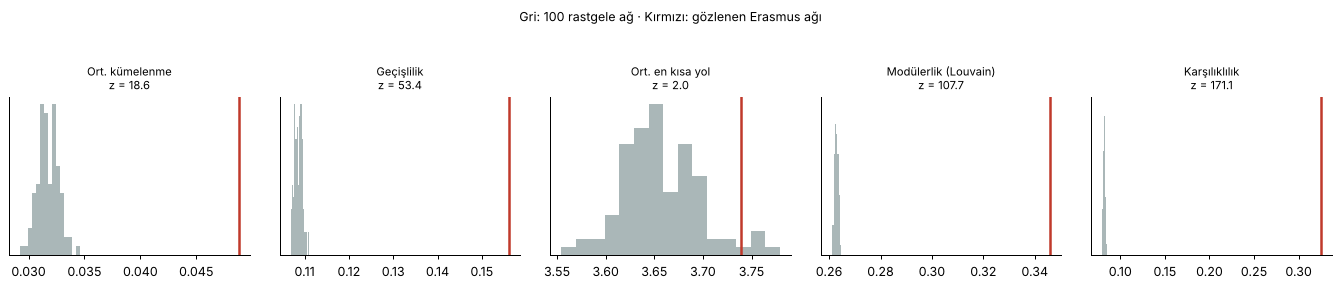

In [12]:
fig, axs = plt.subplots(1, 5, figsize=(15, 3))
etiketler = {"kumelenme": "Ort. kümelenme", "gecislilik": "Geçişlilik", "ort_yol": "Ort. en kısa yol",
             "modulerlik": "Modülerlik (Louvain)", "karsiliklilik": "Karşılıklılık"}
for ax, olcu in zip(axs, etiketler):
    v = [r[olcu] for r in nm["null"]] if olcu != "karsiliklilik" else nm["null_karsilikli"]
    gz = nm["gozlenen"][olcu] if olcu != "karsiliklilik" else nm["gozlenen_karsilikli"]
    ax.hist(v, bins=15, color="#aab7b8")
    ax.axvline(gz, color="#c0392b", lw=2)
    ax.set_title(f"{etiketler[olcu]}\nz = {nmt.loc[olcu, 'z']:,.1f}", fontsize=9); ax.set_yticks([])
plt.suptitle("Gri: 100 rastgele ağ · Kırmızı: gözlenen Erasmus ağı", fontsize=10, y=1.05)
plt.tight_layout(); plt.savefig("fig/null_model.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. Kişisel ileri yöntem

### 6a. Karşılıklılık ve giriş/çıkış dengesizliği
- Ağırlıksız karşılıklılık: A→B varken B→A'nın da var olma oranı.
- Ağırlıklı karşılıklılık (Squartini vd. 2013): r_w = Σ min(w_ij, w_ji) / Σ w_ij — öğrenci akışının ne kadarı "karşılıklı" kısma düşüyor.
- Dengesizlik endeksi: I = (giden − gelen) / (giden + gelen). +1 tamamen gönderen, −1 tamamen alan.

In [13]:
def agirlikli_karsiliklilik(G):
    pay = sum(min(w, G[b][a]["weight"]) for a, b, w in G.edges(data="weight") if G.has_edge(b, a))
    return pay / sum(w for _, _, w in G.edges(data="weight"))


def denge_tablosu(GC):
    d = pd.DataFrame({"giden": dict(GC.out_degree(weight="weight")), "gelen": dict(GC.in_degree(weight="weight"))}).fillna(0)
    d["net_giden"] = d.giden - d.gelen
    d["dengesizlik"] = (d.giden - d.gelen) / (d.giden + d.gelen)
    return d


PROGRAM = ["AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "EL", "HU", "IE", "IT", "LV", "LT", "LU", "MT",
           "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE", "IS", "LI", "NO", "MK", "RS", "TR", "UK"]
denge = denge_tablosu(GC)
dp = denge.loc[[u for u in PROGRAM if u in denge.index]].sort_values("dengesizlik", ascending=False)
dp.to_csv(f"output/dengesizlik_ulke_{YIL}.csv")
SONUC["karsiliklilik"] = {
    "kurum_agirliksiz": nx.reciprocity(G), "kurum_agirlikli": agirlikli_karsiliklilik(G),
    "ulke_agirliksiz": nx.reciprocity(GC), "ulke_agirlikli": agirlikli_karsiliklilik(GC),
}
tr_ = denge.loc["TR"]
SONUC["tr_denge"] = {"giden": int(tr_.giden), "gelen": int(tr_.gelen), "oran": float(tr_.giden / tr_.gelen),
                     "dengesizlik": float(tr_.dengesizlik), "sira_34_ulke": int(list(dp.index).index("TR") + 1),
                     "net_giden": int(tr_.net_giden)}
SONUC["dengesizlik_tablosu"] = dp.round(3).reset_index().rename(columns={"index": "ulke"}).to_dict(orient="records")
print(json.dumps(SONUC["karsiliklilik"], indent=1))
print(dp.round(3).to_string())

# Türkiye'nin partner bazında dengesi
trp = pd.DataFrame({"giden": {b: GC["TR"][b]["weight"] for b in GC.successors("TR")},
                    "gelen": {a: GC[a]["TR"]["weight"] for a in GC.predecessors("TR")}}).fillna(0).astype(int)
trp["toplam"] = trp.giden + trp.gelen
trp = trp.sort_values("toplam", ascending=False)
trp.to_csv(f"output/turkiye_partnerler_{YIL}.csv")
SONUC["tr_partnerler"] = trp.head(10).reset_index().rename(columns={"index": "ulke"}).to_dict(orient="records")
print(trp.head(10).to_string())

{
 "kurum_agirliksiz": 0.3251764773264222,
 "kurum_agirlikli": 0.3180420231049544,
 "ulke_agirliksiz": 0.6986928104575163,
 "ulke_agirlikli": 0.6965339898782656
}
    giden  gelen  net_giden  dengesizlik
TR  16214   6045      10169        0.457
RO   7561   3732       3829        0.339
FR  53843  32618      21225        0.245
SK   3490   2304       1186        0.205
DE  48949  34996      13953        0.166
BG   2020   1573        447        0.124
MK    436    372         64        0.079
IT  43967  37589       6378        0.078
RS    482    417         65        0.072
NL  18237  16105       2132        0.062
LV   2046   1990         56        0.014
EL   6111   6215       -104       -0.008
LT   3540   3682       -142       -0.020
EE   1574   1845       -271       -0.079
PL  13000  15388      -2388       -0.084
BE  12408  14794      -2386       -0.088
ES  48279  57699      -9420       -0.089
AT   7776  10162      -2386       -0.133
HR   2291   3077       -786       -0.146
CZ   7770  10851 

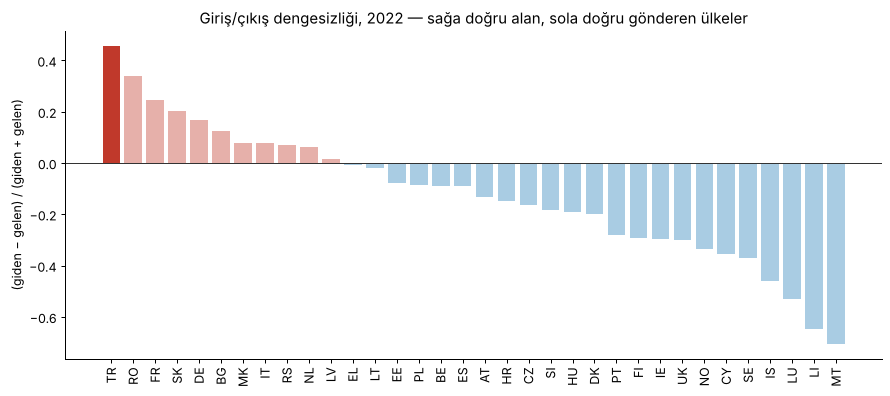

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
renk = ["#c0392b" if u == "TR" else ("#e6b0aa" if v > 0 else "#a9cce3") for u, v in dp.dengesizlik.items()]
ax.bar(dp.index, dp.dengesizlik, color=renk)
ax.axhline(0, color="#333", lw=.8)
ax.set_ylabel("(giden − gelen) / (giden + gelen)")
ax.set_title(f"Giriş/çıkış dengesizliği, {YIL} — sağa doğru alan, sola doğru gönderen ülkeler")
plt.xticks(rotation=90); plt.tight_layout(); plt.savefig("fig/dengesizlik.png", dpi=200); plt.show()

### 6b. Çekim (gravity) modeli

Örneklem: 2022'de Erasmus+ programına katılan 33 ülke + Birleşik Krallık (2014-2020 projeleri sürdüğü için) → 34 × 33 = 1.122 yönlü ülke çifti, sıfır akışlar dahil.

Model (Poisson sözde en çok olabilirlik, PPML — sıfır akışları da kullanabildiği için çekim modellerinde standarttır):

E[F_ij] = exp(β0 + β1 ln Nüfus_i + β2 ln Nüfus_j + β3 ln Mesafe_ij + β4 TR_kaynak + β5 TR_hedef)

- Nüfus: Dünya Bankası (SP.POP.TOTL, 2022). Mesafe: başkentler arası büyük daire mesafesi (km).
- TR kukla değişkenleri, Türkiye'nin büyüklüğü ve mesafesine göre beklenenden **fazla gönderip gönderemediğini** / **az alıp almadığını** test eder.
- Standart hatalar heteroskedasiteye dayanıklı (sandviç, HC0). Karşılaştırma için pozitif akışlarda log-OLS da verilir.
- Sonuçlar ilişki gösterir, nedensellik iddiası taşımaz.

In [15]:
def dunya_bankasi(kodlar, yil=2022):
    """Nüfus ve başkent koordinatlarını Dünya Bankası API'sinden çeker; internet yoksa depodaki kopyayı kullanır."""
    yol = "data/external/ulkeler_worldbank_2022.csv"
    if os.path.exists(yol):
        return pd.read_csv(yol, keep_default_na=False)
    import requests
    wb = {"EL": "GR", "UK": "GB"}
    q = ";".join(wb.get(k, k) for k in kodlar)
    pop = requests.get(f"https://api.worldbank.org/v2/country/{q}/indicator/SP.POP.TOTL?date={yil}&format=json&per_page=100").json()[1]
    cap = requests.get(f"https://api.worldbank.org/v2/country/{q}?format=json&per_page=100").json()[1]
    p = {r["country"]["id"]: r["value"] for r in pop}
    rows = [{"kod": next(k for k in kodlar if wb.get(k, k) == c["iso2Code"]), "wb_kod": c["iso2Code"], "ulke": c["name"],
             "baskent": c["capitalCity"], "boylam": float(c["longitude"]), "enlem": float(c["latitude"]), "nufus_2022": p[c["iso2Code"]]}
            for c in cap]
    os.makedirs("data/external", exist_ok=True)
    pd.DataFrame(rows).to_csv(yol, index=False)
    return pd.DataFrame(rows)


def haversine(a1, o1, a2, o2):
    a1, o1, a2, o2 = map(np.radians, [a1, o1, a2, o2])
    h = np.sin((a2 - a1) / 2) ** 2 + np.cos(a1) * np.cos(a2) * np.sin((o2 - o1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))


def ppml(X, y, maxiter=100):
    """Poisson regresyonu (IRLS) + sandviç standart hata. X sabit sütunu içermeli."""
    b = np.zeros(X.shape[1]); b[0] = np.log(y.mean())
    for _ in range(maxiter):
        mu = np.exp(X @ b)
        z = X @ b + (y - mu) / mu
        W = mu
        b_yeni = np.linalg.solve(X.T @ (W[:, None] * X), X.T @ (W * z))
        if np.max(np.abs(b_yeni - b)) < 1e-10:
            b = b_yeni; break
        b = b_yeni
    mu = np.exp(X @ b)
    A = np.linalg.inv(X.T @ (mu[:, None] * X))
    B = X.T @ (((y - mu) ** 2)[:, None] * X)
    se = np.sqrt(np.diag(A @ B @ A))
    sapma = 2 * np.sum(np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0) - (y - mu))
    sapma0 = 2 * np.sum(np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / y.mean()), 0) - (y - y.mean()))
    return b, se, mu, 1 - sapma / sapma0


def ols(X, y):
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ b
    A = np.linalg.inv(X.T @ X)
    se = np.sqrt(np.diag(A @ (X.T @ ((e ** 2)[:, None] * X)) @ A))
    return b, se, 1 - e.var() / y.var()


def cekim_verisi(GC, wbv):
    w = wbv.set_index("kod")
    ulkeler = [u for u in w.index if u in GC]
    rows = []
    for i in ulkeler:
        for j in ulkeler:
            if i == j:
                continue
            rows.append({"i": i, "j": j, "akis": GC[i][j]["weight"] if GC.has_edge(i, j) else 0,
                         "ln_nufus_i": np.log(w.loc[i, "nufus_2022"]), "ln_nufus_j": np.log(w.loc[j, "nufus_2022"]),
                         "ln_mesafe": np.log(haversine(w.loc[i, "enlem"], w.loc[i, "boylam"], w.loc[j, "enlem"], w.loc[j, "boylam"])),
                         "tr_kaynak": float(i == "TR"), "tr_hedef": float(j == "TR")})
    return pd.DataFrame(rows)


def cekim_modeli(cv):
    degiskenler = ["ln_nufus_i", "ln_nufus_j", "ln_mesafe", "tr_kaynak", "tr_hedef"]
    sonuc = {}
    for ad, deg in [("temel", degiskenler[:3]), ("tr_kuklali", degiskenler)]:
        X = np.column_stack([np.ones(len(cv))] + [cv[d].values for d in deg])
        b, se, mu, r2 = ppml(X, cv.akis.values.astype(float))
        sonuc[ad] = {"katsayi": dict(zip(["sabit"] + deg, b.round(4))), "se": dict(zip(["sabit"] + deg, se.round(4))),
                     "z": dict(zip(["sabit"] + deg, (b / se).round(2))), "pseudo_R2": round(float(r2), 4), "tahmin": mu}
    pos = cv[cv.akis > 0]
    X = np.column_stack([np.ones(len(pos))] + [pos[d].values for d in degiskenler[:3]])
    b, se, r2 = ols(X, np.log(pos.akis.values))
    sonuc["ols_log"] = {"katsayi": dict(zip(["sabit"] + degiskenler[:3], b.round(4))), "se": dict(zip(["sabit"] + degiskenler[:3], se.round(4))),
                        "R2": round(float(r2), 4), "n": int(len(pos))}
    return sonuc


wbv = dunya_bankasi(PROGRAM)
cv = cekim_verisi(GC, wbv)
cm = cekim_modeli(cv)
cv["beklenen_temel"] = cm["temel"]["tahmin"]
tr_bek_gid = cv.loc[cv.i == "TR", "beklenen_temel"].sum(); tr_gid = cv.loc[cv.i == "TR", "akis"].sum()
tr_bek_gel = cv.loc[cv.j == "TR", "beklenen_temel"].sum(); tr_gel = cv.loc[cv.j == "TR", "akis"].sum()
SONUC["cekim"] = {k: {kk: vv for kk, vv in v.items() if kk != "tahmin"} for k, v in cm.items()}
SONUC["cekim"]["ornek"] = {"ulke": int(cv.i.nunique()), "cift": int(len(cv)), "sifir_akis": int((cv.akis == 0).sum()),
                           "ogrenci": int(cv.akis.sum())}
SONUC["cekim"]["tr_beklenen"] = {"giden_gercek": int(tr_gid), "giden_beklenen": float(tr_bek_gid),
                                 "gelen_gercek": int(tr_gel), "gelen_beklenen": float(tr_bek_gel)}
for ad in ["temel", "tr_kuklali", "ols_log"]:
    print(f"\n== {ad} ==")
    print(pd.DataFrame({k: SONUC["cekim"][ad][k] for k in ["katsayi", "se"] + (["z"] if "z" in SONUC["cekim"][ad] else [])}).to_string())
    print("uyum:", SONUC["cekim"][ad].get("pseudo_R2", SONUC["cekim"][ad].get("R2")))
print("\nTürkiye (temel modele göre):", {k: round(v) for k, v in SONUC["cekim"]["tr_beklenen"].items()})
b = SONUC["cekim"]["tr_kuklali"]["katsayi"]
print(f"TR_kaynak etkisi: e^{b['tr_kaynak']:.2f} = {np.exp(b['tr_kaynak']):.2f} kat | TR_hedef etkisi: e^{b['tr_hedef']:.2f} = {np.exp(b['tr_hedef']):.2f} kat")


== temel ==
            katsayi      se      z
sabit      -17.6194  1.4496 -12.15
ln_nufus_i   0.8763  0.0437  20.04
ln_nufus_j   0.6516  0.0436  14.93
ln_mesafe   -0.2639  0.0810  -3.26
uyum: 0.6659

== tr_kuklali ==
            katsayi      se      z
sabit      -21.6255  1.6867 -12.82
ln_nufus_i   0.9448  0.0463  20.42
ln_nufus_j   0.7246  0.0451  16.07
ln_mesafe   -0.0146  0.0936  -0.16
tr_kaynak   -1.1880  0.2559  -4.64
tr_hedef    -1.9928  0.2421  -8.23
uyum: 0.7216

== ols_log ==
            katsayi      se
sabit      -15.8007  0.8174
ln_nufus_i   0.7642  0.0294
ln_nufus_j   0.6118  0.0255
ln_mesafe   -0.2665  0.0627
uyum: 0.5234

Türkiye (temel modele göre): {'giden_gercek': 16037, 'giden_beklenen': 36569, 'gelen_gercek': 5603, 'gelen_beklenen': 27606}
TR_kaynak etkisi: e^-1.19 = 0.30 kat | TR_hedef etkisi: e^-1.99 = 0.14 kat


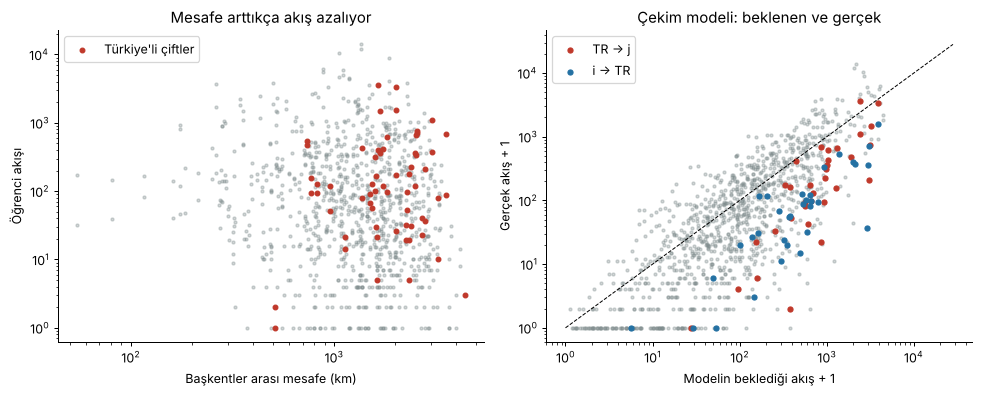

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
p = cv[cv.akis > 0]
ax[0].scatter(np.exp(p.ln_mesafe), p.akis, s=6, alpha=.35, color="#7f8c8d")
t = p[(p.i == "TR") | (p.j == "TR")]
ax[0].scatter(np.exp(t.ln_mesafe), t.akis, s=14, color="#c0392b", label="Türkiye'li çiftler")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("Başkentler arası mesafe (km)"); ax[0].set_ylabel("Öğrenci akışı")
ax[0].set_title("Mesafe arttıkça akış azalıyor"); ax[0].legend()
ax[1].scatter(cv.beklenen_temel + 1, cv.akis + 1, s=6, alpha=.35, color="#7f8c8d")
tt = cv[cv.i == "TR"]; ax[1].scatter(tt.beklenen_temel + 1, tt.akis + 1, s=16, color="#c0392b", label="TR → j")
tt = cv[cv.j == "TR"]; ax[1].scatter(tt.beklenen_temel + 1, tt.akis + 1, s=16, color="#2471a3", label="i → TR")
lim = [1, cv.akis.max() * 2]; ax[1].plot(lim, lim, "k--", lw=.8)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("Modelin beklediği akış + 1"); ax[1].set_ylabel("Gerçek akış + 1")
ax[1].set_title("Çekim modeli: beklenen ve gerçek"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig/cekim_modeli.png", dpi=200); plt.show()

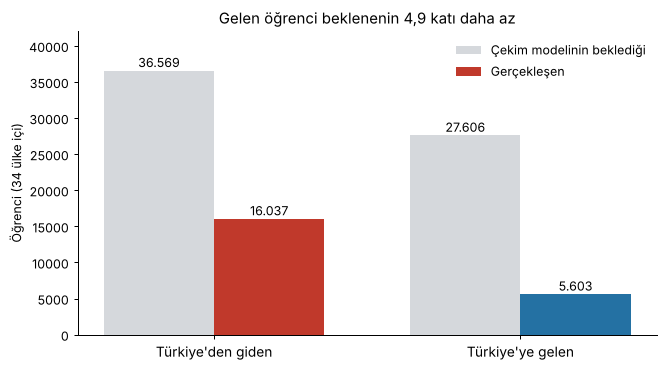

In [17]:
# Türkiye için beklenen ve gerçekleşen akış (sunum ve poster için tek bakışta okunur özet)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(2); gen = 0.36
bek = [tr_bek_gid, tr_bek_gel]; ger = [tr_gid, tr_gel]
b1 = ax.bar(x - gen / 2, bek, gen, color="#d5d8dc", label="Çekim modelinin beklediği")
b2 = ax.bar(x + gen / 2, ger, gen, color=["#c0392b", "#2471a3"], label="Gerçekleşen")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 500, f"{b.get_height():,.0f}".replace(",", "."), ha="center", fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(["Türkiye'den giden", "Türkiye'ye gelen"], fontsize=11)
ax.set_ylabel("Öğrenci (34 ülke içi)"); ax.legend(frameon=False); ax.set_ylim(0, max(bek) * 1.15)
ax.set_title(f"Gelen öğrenci beklenenin {tr_bek_gel / tr_gel:.1f} katı daha az".replace(".", ","), fontsize=12)
plt.tight_layout(); plt.savefig("fig/tr_beklenen.png", dpi=220); plt.show()

### 6c. Yıllar arası değişim

Aynı adımlar (filtre, ülke ağı, karşılıklılık, dengesizlik, çekim modeli) elde bulunan diğer yılların dosyalarına da uygulanır (2019 pandemi öncesi, 2021 pandemi yılı).
Kurum adları yıllar ve dönemler arasında farklı yazıldığı için karşılaştırma **ülke düzeyinde** yapılır.
`data/raw/` klasöründe bulunan her yıl otomatik olarak eklenir.

In [18]:
YILLAR = [y for y in [2019, 2020, 2021, 2022] if os.path.exists(f"data/raw/Erasmus-KA1-Mobility-Data-{y}.xlsx") or os.path.exists(f"data/processed/ogrenci_{y}.csv.gz")]
yillik = []
for y in YILLAR:
    o = ogr if y == YIL else ogrenci_verisi(y)
    uk, _ = kenar_listeleri(o)
    gc = yonlu_ag(uk)
    d = denge_tablosu(gc)
    cvy = cekim_verisi(gc, wbv); cmy = cekim_modeli(cvy)
    yillik.append({
        "yil": y, "ogrenci": int(o.kisi.sum()), "ulke": gc.number_of_nodes(), "ulke_kenar": gc.number_of_edges(),
        "ulke_yogunluk": nx.density(gc), "karsiliklilik_ulke": nx.reciprocity(gc),
        "karsiliklilik_ulke_agirlikli": agirlikli_karsiliklilik(gc),
        "tr_giden": int(d.loc["TR", "giden"]), "tr_gelen": int(d.loc["TR", "gelen"]),
        "tr_oran": float(d.loc["TR", "giden"] / d.loc["TR", "gelen"]), "tr_dengesizlik": float(d.loc["TR", "dengesizlik"]),
        "mesafe_esnekligi": float(cmy["temel"]["katsayi"]["ln_mesafe"]),
        "tr_kaynak_katsayi": float(cmy["tr_kuklali"]["katsayi"]["tr_kaynak"]),
        "tr_hedef_katsayi": float(cmy["tr_kuklali"]["katsayi"]["tr_hedef"]),
        "tr_ilk3_hedef": [x for x in sorted(gc.successors("TR"), key=lambda b: -gc["TR"][b]["weight"])[:3]],
    })
    if y != YIL:
        uk.to_csv(f"output/kenar_listesi_ulke_{y}.csv", index=False)
yt = pd.DataFrame(yillik).set_index("yil")
SONUC["yillar"] = yt.reset_index().to_dict(orient="records")
print(yt.T.to_string())

yil                                   2022
ogrenci                             365590
ulke                                   176
ulke_kenar                            3060
ulke_yogunluk                     0.099351
karsiliklilik_ulke                0.698693
karsiliklilik_ulke_agirlikli      0.696534
tr_giden                             16214
tr_gelen                              6045
tr_oran                           2.682217
tr_dengesizlik                    0.456849
mesafe_esnekligi                   -0.2639
tr_kaynak_katsayi                   -1.188
tr_hedef_katsayi                   -1.9928
tr_ilk3_hedef                 [PL, DE, IT]


In [19]:
if len(yt) > 1:
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    ax[0].plot(yt.index, yt.tr_giden, "o-", color="#c0392b", label="Giden"); ax[0].plot(yt.index, yt.tr_gelen, "o-", color="#2471a3", label="Gelen")
    ax[0].set_title("Türkiye: giden ve gelen öğrenci"); ax[0].legend(); ax[0].set_xticks(yt.index)
    ax[1].plot(yt.index, yt.tr_oran, "o-", color="#c0392b"); ax[1].set_title("Türkiye: giden / gelen oranı"); ax[1].set_xticks(yt.index)
    ax[2].plot(yt.index, yt.karsiliklilik_ulke_agirlikli, "o-", color="#555"); ax[2].set_title("Ülke ağı ağırlıklı karşılıklılık"); ax[2].set_xticks(yt.index)
    plt.tight_layout(); plt.savefig("fig/yillar.png", dpi=200); plt.show()
else:
    print("Tek yıl verisi var; yıllar arası grafik için data/raw/ klasörüne başka yılların dosyalarını ekleyin.")

Tek yıl verisi var; yıllar arası grafik için data/raw/ klasörüne başka yılların dosyalarını ekleyin.


## 7. Görselleştirme için dışa aktarma

36 bin kurumu tek ekrana basmak okunaksız olacağından, etkileşimli ağ için **öğrenci hacmine göre en büyük 600 kurum** ve aralarındaki akışlar seçilir (filtrelenmiş görünüm).
Bu kurumlar toplam öğrenci hareketinin önemli bir kısmını taşır; oranı aşağıda yazdırılır. Konumlar kuvvet yönelimli yay düzeniyle (`spring_layout`, sabit tohum) her kurumun en güçlü 6 bağından oluşan omurga üzerinde hesaplanır.

In [20]:
N_GORSEL = 600
secili = sorted(guc, key=guc.get, reverse=True)[:N_GORSEL]
S = G.subgraph(secili).copy()
SU = yonsuz_ag(S)
pay = sum(w for a, b, w in G.edges(data="weight") if a in S and b in S) / sum(w for *_, w in G.edges(data="weight"))
# Okunur bir düzen için "omurga": her kurumun en güçlü 6 bağı. Konumlar omurga üzerinde hesaplanır,
# genel görünümde yalnızca omurga çizilir; bir kuruma tıklanınca tüm bağları gösterilir.
B = nx.Graph(); B.add_nodes_from(SU)
for n in SU:
    for m, d in sorted(SU[n].items(), key=lambda x: -x[1]["weight"])[:6]:
        B.add_edge(n, m)
pos = nx.spring_layout(B, seed=SEED, k=2.2 / np.sqrt(len(B)), iterations=400)
topluluk_adlari_sirasi = sorted(set(topluluk[n] for n in secili), key=lambda c: -sum(1 for n in secili if topluluk[n] == c))
gorsel = {
    "yil": YIL, "kapsanan_akis_orani": pay,
    "dugumler": [{"id": n, "ulke": n[:2], "ad": n[5:], "x": float(pos[n][0]), "y": float(pos[n][1]),
                  "giden": int(cikis.get(n, 0)), "gelen": int(giris.get(n, 0)), "derece": int(derece[n]),
                  "pagerank_sira": int((merk.pagerank > merk.loc[n, "pagerank"]).sum()) + 1,
                  "topluluk": int(topluluk[n])} for n in secili],
    "kenarlar": [{"s": a, "t": b, "w": int(w)} for a, b, w in S.edges(data="weight")],
    "omurga": [[a, b] for a, b in B.edges()],
}
json.dump(gorsel, open("output/gorsel_ag.json", "w"), ensure_ascii=False)
print(f"{len(S)} kurum, {S.number_of_edges()} kenar; toplam öğrenci akışının %{100*pay:.1f}'i bu alt ağda.")
SONUC["gorsel"] = {"dugum": len(S), "kenar": S.number_of_edges(), "akis_payi": pay}

600 kurum, 38177 kenar; toplam öğrenci akışının %69.2'i bu alt ağda.


In [21]:
def jsonla(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
json.dump(SONUC, open("output/sonuclar.json", "w"), ensure_ascii=False, indent=1, default=jsonla)
print("Tüm sonuçlar output/sonuclar.json dosyasına yazıldı.")

Tüm sonuçlar output/sonuclar.json dosyasına yazıldı.
